# Autoencoder convolucional


Pasos: cargar datos, definir el modelo, entrenar, generar 200 caras y sacar el `submission.csv`.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

I0000 00:00:1792694032.335737   75700 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792694032.378022   75700 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792694033.514721   75700 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


##  Datos

30.000 caras de 64x64 en `CelebAMask/images/0.jpg ... 29999.jpg`. Las pasamos a RGB y a [0, 1] (la salida del decoder es una sigmoide, así que los datos tienen que estar en ese rango). Separamos 90 % para entrenar y 10 % para validación; la validación solo sirve para saber cuándo parar, no se usa para generar.

In [2]:
DATA_DIR = "CelebAMask/images"
N_IMAGES = 30000

x = np.array([cv2.cvtColor(cv2.imread(f"{DATA_DIR}/{i}.jpg"), cv2.COLOR_BGR2RGB) for i in range(N_IMAGES)],
             dtype="float32") / 255.0
print(x.shape, x.min(), x.max())      # (30000, 64, 64, 3) 0.0 1.0

# split 90 / 10 sobre índices barajados
idx = np.random.permutation(len(x))
n_val = int(0.1 * len(x))
x_val, x_train = x[idx[:n_val]], x[idx[n_val:]]
del x                                  # liberamos ~1,5 GB de RAM (sino me petaba el visual)
print(x_train.shape, x_val.shape)

(30000, 64, 64, 3) 0.0 1.0
(27000, 64, 64, 3) (3000, 64, 64, 3)


## Modelo

Encoder y decoder por separado porque luego usamos cada uno solo (el encoder para sacar latentes, el decoder para generar). Las capas están escritas una a una para ver la estructura.

- **Encoder**: 3 bloques `Conv (stride 2) -> GroupNorm -> LeakyReLU`, con 64, 128 y 256 filtros. Cada bloque reduce a la mitad: 64 -> 32 -> 16 -> 8 (paramos en 8x8, antes llegábamos a 4x4). Luego `Flatten` y una `Dense` al latente de **64** números (sin activación). Pasamos de 12288 valores a 64.
- **Decoder**: el espejo. `Dense` a 8x8x256 y 3 `Conv2DTranspose` que duplican el tamaño hasta 64x64. La última lleva sigmoide para que la salida esté en [0, 1].
- **GroupNorm en vez de BatchNorm**: normaliza por grupos de canales dentro de cada imagen, así no depende del batch y el decoder se comporta igual al entrenar y al generar con `z` nuevos.
- Al final compilamos con **MSE** (el objetivo del AE es reconstruir la propia entrada) y Adam con lr 1e-3.

In [3]:
LATENT_DIM = 64

enc_in = keras.Input(shape=(64, 64, 3))

x = layers.Conv2D(64, 3, strides=2, padding="same", use_bias=False)(enc_in)    # 64x64x3  -> 32x32x64
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, 3, strides=2, padding="same", use_bias=False)(x)        # 32x32x64 -> 16x16x128
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, 3, strides=2, padding="same", use_bias=False)(x)        # 16x16x128 -> 8x8x256
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Flatten()(x)                                                        # 8x8x256 -> 16384
z = layers.Dense(LATENT_DIM)(x)                                                # 16384 -> 64 (latente)

encoder = keras.Model(enc_in, z, name="encoder")

encoder.summary()

I0000 00:00:1792694037.955404   75700 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1203 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization             │ (None, 32, 32, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_1           │ (None, 16, 16, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_2           │ (None, 8, 8, 256)      │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,419,904 (5.42 MB)

 Trainable params: 1,419,904 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
dec_in = keras.Input(shape=(LATENT_DIM,))

x = layers.Dense(8 * 8 * 256, use_bias=False)(dec_in)                          # 64 -> 16384
x = layers.Reshape((8, 8, 256))(x)                                             # 16384 -> 8x8x256
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", use_bias=False)(x)   # 8x8x256   -> 16x16x128
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", use_bias=False)(x)    # 16x16x128 -> 32x32x64
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

out = layers.Conv2DTranspose(3, 3, strides=2, padding="same", activation="sigmoid")(x)   # 32x32x64 -> 64x64x3

decoder = keras.Model(dec_in, out, name="decoder")

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16384)          │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_3           │ (None, 8, 8, 256)      │           512 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       294,912 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_4           │ (None, 16, 16, 128)    │           256 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │        73,728 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_5           │ (None, 32, 32, 64)     │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 3)      │         1,731 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,419,843 (5.42 MB)

 Trainable params: 1,419,843 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
ae_in = keras.Input(shape=(64, 64, 3))
autoencoder = keras.Model(ae_in, decoder(encoder(ae_in)), name="autoencoder")

# Compilación: pérdida MSE y optimizador Adam
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 64)             │     1,419,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 64, 64, 3)      │     1,419,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,839,747 (10.83 MB)

 Trainable params: 2,839,747 (10.83 MB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento

El modelo ya está compilado. Como el objetivo del AE es la propia entrada, el dataset da pares `(x, x)`. Lo montamos con `tf.data` en CPU para que la GPU (2 GB) solo reciba lotes y no el array entero.

- `EarlyStopping`: para si la validación no mejora en 6 épocas y se queda con los mejores pesos.
- `ReduceLROnPlateau`: baja el learning rate a la mitad si se estanca 2 épocas.

El modelo base llegó a las 50 épocas (el máximo) con un MSE de validación de ~0.0056, todavía mejorando un poco, así que subimos el máximo a 100 (el `EarlyStopping` decide cuándo parar).

Epoch 1/100


I0000 00:00:1792694042.388576   75862 service.cc:153] XLA service 0x78294004f440 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792694042.388593   75862 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1792694042.459782   75862 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792694042.807339   75862 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1792694042.830718   75862 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5039__.65


  7/422 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0882  

I0000 00:00:1792694052.562357   75862 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


420/422 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0363

I0000 00:00:1792694060.282304   75859 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5039__.65


422/422 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - loss: 0.0239 - val_loss: 0.0136 - learning_rate: 0.0010
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0116 - val_loss: 0.0102 - learning_rate: 0.0010
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0095 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0089 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0086 - val_loss: 0.0085 - learning_rate: 0.0010
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0084 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 7/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0082 - val_loss: 0.0083 - learning_rate: 0.0010
Epoch 8/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0081 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 9/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0081 - val_loss: 0.0082 - learning_rate: 0.0010
Epo

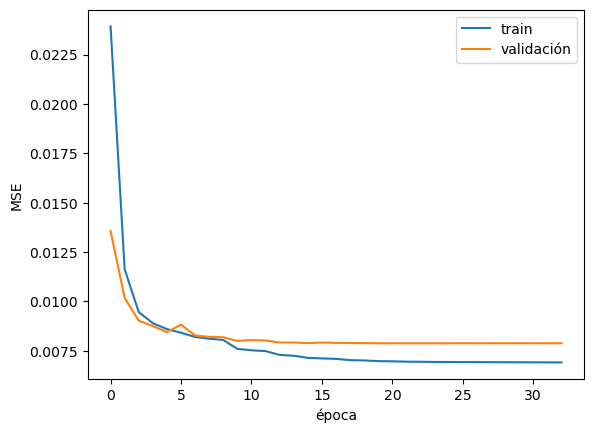

In [6]:
EPOCHS = 100
BATCH_SIZE = 64          # con 2 GB de GPU, 128 puede dar error de memoria

# Los datos se quedan en la CPU y a la GPU solo llegan los lotes. Si pasamos x_train directamente a fit(),
# TensorFlow intenta copiar el array entero (1,3 GB) a la GPU y con 2 GB falla.
# El par (x, x) se forma con .map para no duplicar el array en memoria.
with tf.device("/CPU:0"):
    train_ds = (tf.data.Dataset.from_tensor_slices(x_train)
                .shuffle(1024, seed=SEED).map(lambda x: (x, x)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
    val_ds = (tf.data.Dataset.from_tensor_slices(x_val)
              .map(lambda x: (x, x)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

history = autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ],
)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("MSE"); plt.legend(); plt.show()

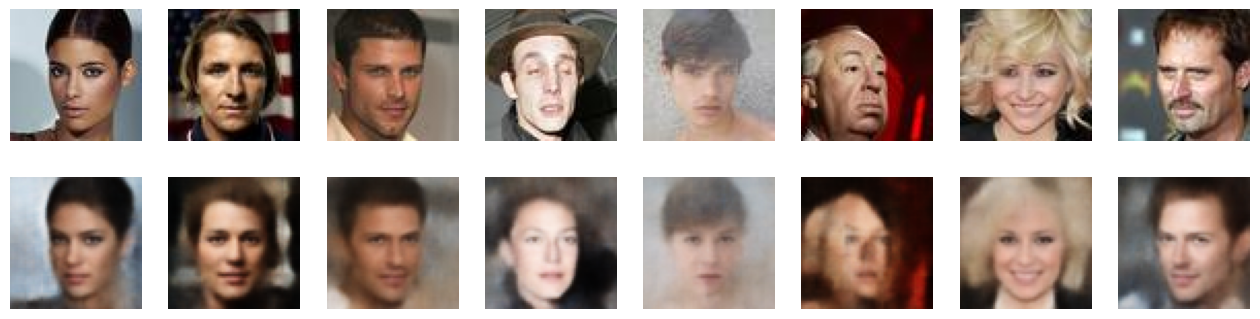

In [7]:
# Reconstrucciones de validación
rec = autoencoder.predict(x_val[:8], verbose=0)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(x_val[i]); axes[1, i].imshow(np.clip(rec[i], 0, 1))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.show()

## Generar caras

Un AE no sabe generar solo: si le das un `z` al azar casi siempre cae en una zona del latente que no ha visto y sale ruido. Lo que hacemos es mirar dónde caen las caras reales en el espacio latente y muestrear de ahí:

1. Codificamos 5.000 imágenes de train -> 5.000 vectores `z`.
2. Calculamos su **media** y su **matriz de covarianza completa** (la covarianza recoge que las dimensiones del latente están relacionadas entre sí; con solo la diagonal salía bastante peor).
3. Sacamos 200 `z` nuevos de esa gaussiana y los pasamos por el decoder.

Esto no está en las diapositivas, hay que decirlo en la presentación.

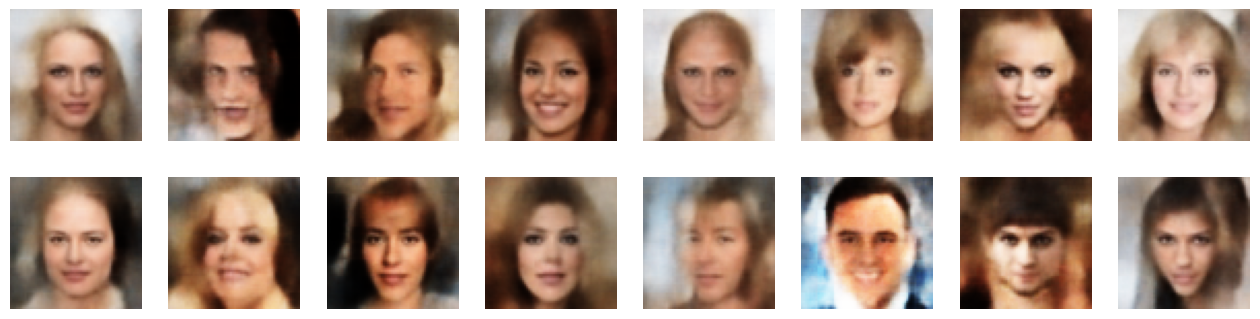

In [8]:
N_SAMPLES = 200

sub = np.random.default_rng(SEED).choice(len(x_train), 5000, replace=False)
z_train = encoder.predict(x_train[sub], verbose=0)
mu, cov = z_train.mean(axis=0), np.cov(z_train, rowvar=False)

z_new = np.random.default_rng(SEED).multivariate_normal(mu, cov, size=N_SAMPLES).astype("float32")
faces = np.clip(decoder.predict(z_new, verbose=0), 0, 1)       # (200, 64, 64, 3) en [0, 1]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, img in zip(axes.flat, faces):
    ax.imshow(img); ax.axis("off")
plt.show()

## CSV para Kaggle

Kaggle evalúa en **escala de grises**, así que pasamos las 200 caras a uint8, las convertimos a gris y aplanamos cada una en 4096 píxeles. El CSV tiene la columna `ID` (1..200) y los 4096 píxeles, sin columna `Usage` (lo dijo el profe). Tiene que salir de forma `(200, 4097)`.

In [9]:
faces_u8 = np.round(faces * 255).astype("uint8")
gray = np.array([cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in faces_u8])    # (200, 64, 64)

df = pd.DataFrame(gray.reshape(N_SAMPLES, -1))
df.insert(0, "ID", range(1, N_SAMPLES + 1))
df.to_csv("submission_ae_simple.csv", index=False)
print(df.shape)       # (200, 4097)

(200, 4097)


## FID local

Kaggle puntúa con **FID** (más bajo es mejor): compara las caras generadas con las reales usando los rasgos de una red InceptionV3. Para no gastar subidas lo calculamos en local con el InceptionV3 de Keras (ImageNet), usado **solo para evaluar** (no se entrena ni se ajusta).

- Los valores **no coinciden** con los de Kaggle (no es el Inception oficial), pero sirven para comparar modelos entre sí.
- Con 200 imágenes el FID es ruidoso y sale más alto de lo normal; con 1000 es más estable.
- Referencias: caras **reales** (200) dan ~36, el mejor valor posible con este método; **ruido** da ~583.
- En nuestra ejecución: CSV de 200 imágenes ~113 en local (113.5 en Kaggle) y ~93 con 1000 imágenes.

In [10]:
REF_N = 3000     # caras reales de train que usamos como referencia
N_FID = 1000     # caras generadas para el FID estable

# InceptionV3 de ImageNet sin la capa final: devuelve un vector de 2048 por imagen
inception = keras.applications.InceptionV3(include_top=False, pooling="avg", weights="imagenet",
                                           input_shape=(299, 299, 3))


def rasgos(imgs, batch=16):
    """imgs (N, 64, 64, 3) en [0, 1]. Igual que el evaluador: gris de 8 bits -> 3 canales -> 299x299."""
    g = np.round(imgs.mean(axis=-1) * 255).clip(0, 255) / 255.0
    out = []
    for i in range(0, len(g), batch):
        b = np.repeat(g[i:i + batch, ..., None], 3, axis=-1).astype("float32")
        b = tf.image.resize(b, (299, 299), method="bilinear")
        out.append(inception.predict(keras.applications.inception_v3.preprocess_input(b * 255.0), verbose=0))
    return np.concatenate(out)


def estadisticos(f):
    return f.mean(axis=0), np.cov(f, rowvar=False)


def fid_entre(mu1, s1, mu2, s2):
    """FID = |mu1 - mu2|^2 + Tr(S1 + S2 - 2 (S1 S2)^(1/2)). La traza de la raíz sale de los autovalores de S1 S2."""
    eig = np.linalg.eigvals(s1 @ s2)
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1) + np.trace(s2) - 2 * np.sqrt(np.clip(eig.real, 0, None)).sum())


mu_ref, sig_ref = estadisticos(rasgos(x_train[:REF_N]))      # estadísticos de las caras reales


def fid_local(imgs):
    mu_i, sig_i = estadisticos(rasgos(imgs))
    return fid_entre(mu_i, sig_i, mu_ref, sig_ref)

W0000 00:00:1792694358.124260   75863 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.26GiB (rounded to 1352737280)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1792694358.127633   75863 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1792694358.127637   75863 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 232, Chunks in use: 232. 58.0KiB allocated for chunks. 58.0KiB in use in bin. 17.0KiB client-requested in use in bin.
I0000 00:00:1792694358.127643   75863 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 179, Chunks in use: 179. 120.5KiB allocated for chunks. 120.5KiB in use in bin. 111.9KiB client-requested in use in bin.
I0000 00:00:1792694358.127645   75863 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 69, Chunks in use: 69. 95.8KiB al

W0000 00:00:1792694427.951505   75863 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.98GiB (rounded to 2130473472)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1792694427.955092   75863 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1792694427.955106   75863 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 235, Chunks in use: 235. 58.8KiB allocated for chunks. 58.8KiB in use in bin. 17.0KiB client-requested in use in bin.
I0000 00:00:1792694427.955122   75863 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 179, Chunks in use: 179. 120.5KiB allocated for chunks. 120.5KiB in use in bin. 111.9KiB client-requested in use in bin.
I0000 00:00:1792694427.955130   75863 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 69, Chunks in use: 69. 95.8KiB al

In [11]:
# 1) El CSV que subimos (200 imágenes en gris, tal cual se leen en Kaggle)
px = pd.read_csv("submission_ae_simple.csv").iloc[:, 1:].values.reshape(-1, 64, 64) / 255.0
fid_csv = fid_local(np.repeat(px[..., None], 3, axis=-1))

# 2) FID estable: 1000 caras generadas con el mismo método
z_big = np.random.default_rng(SEED + 1).multivariate_normal(mu, cov, size=N_FID).astype("float32")
fid_estable = fid_local(np.clip(decoder.predict(z_big, batch_size=32, verbose=0), 0, 1))

# 3) Referencias: caras reales de validación y ruido
fid_suelo = fid_local(x_val[:200])
fid_ruido = fid_local(np.random.default_rng(SEED).random((200, 64, 64, 3)).astype("float32"))

print(f"FID local del CSV (200 imgs):       {fid_csv:.1f}")
print(f"FID local con {N_FID} imgs generadas:  {fid_estable:.1f}")
print(f"Referencia reales (200 imgs):       {fid_suelo:.1f}")
print(f"Referencia ruido  (200 imgs):       {fid_ruido:.1f}")

FID local del CSV (200 imgs):       102.9
FID local con 1000 imgs generadas:  89.7
Referencia reales (200 imgs):       35.9
Referencia ruido  (200 imgs):       581.3


## Registro de pruebas

Anotamos aquí cada versión con el FID local de la última celda (más bajo es mejor). `val_loss` es el MSE de validación del entrenamiento.

| # | Cambio | FID CSV (200) | FID (1000) | val_loss | Kaggle |
|---|---|---|---|---|---|
| 0 | Base: AE de 4 bloques (32-256 filtros, hasta 4x4), BatchNorm, latente 128, 50 épocas, una gaussiana | 111.6 | 91.6 | 0.0056 | 113.5 |
| 1 | Latente 64 + filtros 64/128/256 (hasta 8x8) + GroupNorm + 100 épocas (todos a la vez; paró en la época 33) | 102.9 | 89.7 | 0.0079 | 105.4 |